# Unidro MineProblem: RQD Quality Assessment with YOLOv8

# Part 2: Quality Assessment (Object Detection & RQD Calculation)

In [9]:
import os
import shutil
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split

import torch

# Check GPU availability (GTX 1660 Ti)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if device == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU Name: NVIDIA GeForce GTX 1660 Ti


## Mathematical Formulation of RQD

$$
\Large
\begin{aligned}
&RQD = \frac{\sum l_{10\text{cm}}}{l_t} \times 100\% \\
&l_{10\text{cm}} = \frac{\text{width}_{\text{pixel}}}{\text{image\_width}_{\text{pixel}}} \times 1.1\text{ m}
\end{aligned}
$$

| RQD Range (%) | Group | Description |
| :---: | :---: | :---: |
| $[0, 25]$ | 1 | Completely weathered rock |
| $[25, 50)$ | 2 | Weathered rock |
| $[50, 75)$ | 3 | Moderately weathered rock |
| $[75, 90)$ | 4 | Hard rock |
| $[90, 100]$ | 5 | Sound rock (unweathered) |

## Data Preparation for YOLOv8

### Converting Bounding Boxes to YOLO Normalized Format

In [10]:
DATA_DIR = './data'
TRAIN_IMG_DIR = os.path.join(DATA_DIR, 'train')
TEST_IMG_DIR = os.path.join(DATA_DIR, 'test-rqd')
LABEL_EXCEL = os.path.join(DATA_DIR, 'label.xlsx')
FROM_TO_EXCEL = os.path.join(DATA_DIR, 'from-to-rqd.xlsx')
YOLO_DATASET_DIR = './yolo_dataset'

class YOLODatasetBuilder:
    def __init__(self, train_img_dir, label_excel, output_dir, val_split=0.2, seed=42):
        self.train_img_dir = train_img_dir
        self.label_excel = label_excel
        self.output_dir = output_dir
        self.val_split = val_split
        self.seed = seed
        self.class_map = {'+10cm rock': 0, 'wood': 1}

    def _find_image_file(self, image_name):
        for ext in ['.jpg', '.JPG', '.png', '.PNG', '.jpeg']:
            candidate = os.path.join(self.train_img_dir, f"{image_name}{ext}")
            if os.path.exists(candidate):
                return candidate
        return None

    def build_dataset(self):
        df = pd.read_excel(self.label_excel)
        unique_images = df['image_name'].dropna().astype(str).unique().tolist()
        
        if len(unique_images) > 1:
            train_imgs, val_imgs = train_test_split(
                unique_images, test_size=self.val_split, random_state=self.seed
            )
        else:
            train_imgs, val_imgs = unique_images, unique_images

        splits = {'train': train_imgs, 'val': val_imgs}
        for split_name, img_list in splits.items():
            img_out_dir = os.path.join(self.output_dir, 'images', split_name)
            lbl_out_dir = os.path.join(self.output_dir, 'labels', split_name)
            os.makedirs(img_out_dir, exist_ok=True)
            os.makedirs(lbl_out_dir, exist_ok=True)

            for img_name in img_list:
                src_img = self._find_image_file(img_name)
                if src_img is None:
                    continue
                shutil.copy(src_img, os.path.join(img_out_dir, os.path.basename(src_img)))

                # Convert bounding boxes: (xmin, ymin, width, height) -> (x_center, y_center, w, h) normalized
                img_Boxes = df[df['image_name'] == img_name]
                yolo_lines = []
                for _, row in img_Boxes.iterrows():
                    label_str = str(row['label_name']).strip()
                    if label_str not in self.class_map:
                        continue
                    cls_id = self.class_map[label_str]
                    img_w = float(row['image_width'])
                    img_h = float(row['image_height'])

                    x_center = (float(row['xmin']) + float(row['width']) / 2.0) / img_w
                    y_center = (float(row['ymin']) + float(row['height']) / 2.0) / img_h
                    norm_w = float(row['width']) / img_w
                    norm_h = float(row['height']) / img_h

                    # Clip values strictly to [0, 1]
                    x_center = np.clip(x_center, 0.0, 1.0)
                    y_center = np.clip(y_center, 0.0, 1.0)
                    norm_w = np.clip(norm_w, 0.0, 1.0)
                    norm_h = np.clip(norm_h, 0.0, 1.0)

                    yolo_lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}")

                lbl_file = os.path.join(lbl_out_dir, f"{img_name}.txt")
                with open(lbl_file, 'w', encoding='utf-8') as f:
                    f.write('\n'.join(yolo_lines))

        # Write dataset.yaml for Ultralytics YOLOv8
        yaml_config = {
            'path': os.path.abspath(self.output_dir),
            'train': 'images/train',
            'val': 'images/val',
            'names': {0: '+10cm rock', 1: 'wood'}
        }
        yaml_path = os.path.join(self.output_dir, 'dataset.yaml')
        with open(yaml_path, 'w', encoding='utf-8') as f:
            yaml.dump(yaml_config, f, sort_keys=False)
        return yaml_path

builder = YOLODatasetBuilder(TRAIN_IMG_DIR, LABEL_EXCEL, YOLO_DATASET_DIR)
yaml_path = builder.build_dataset()
print(f"YOLO dataset prepared successfully. Config saved to: {yaml_path}")

YOLO dataset prepared successfully. Config saved to: ./yolo_dataset\dataset.yaml


## Model Configuration & Training (YOLOv8 on GTX 1660 Ti)

To install `ultralytics` in your VS Code environment if not already installed, uncomment and run `!pip install ultralytics`.

In [11]:
# !pip install -q ultralytics
from ultralytics import YOLO

torch.manual_seed(42)

# Load pretrained YOLOv8s (Small) or YOLOv8n (Nano) - optimized for 6GB VRAM on GTX 1660 Ti
model = YOLO('yolov8n.pt')

# Train the model on custom core-box dataset
train_results = model.train(
    data=yaml_path,
    epochs=25,
    imgsz=640,
    batch=8,          # Safe batch size for GTX 1660 Ti (6GB VRAM)
    device=device,
    project='unidro_yolo',
    name='exp_rqd',
    exist_ok=True,
    verbose=True
)

Ultralytics 8.4.163  Python-3.12.7 torch-2.13.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 Ti, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./yolo_dataset\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_rqd, nbs=64, nms=None, opset=No

## RQD Post-Processing & Run Segmentation Engine

### Row Clustering, Purple Wood Fallback & Secondary Fracture Merging
1. **Row Assignment:** Core boxes have horizontal troughs (rows). We cluster object $y$-centers into rows from top to bottom, and sort objects within each row from left to right ($x$-center).
2. **Secondary Fracture Merging:** As explained in the supplementary notes, vertical breaks with tiny horizontal separation inside the same row are mechanical/secondary fractures and are merged if needed.
3. **HSV Purple Wood Backup:** Since all separator woods are painted purple, an OpenCV HSV color filter is also included as a hybrid safeguard if the detector misses any wood block.

In [12]:
class CoreBoxRQDCalculator:
    def __init__(self, box_length_m=1.1, min_rock_m=0.10):
        self.box_length_m = box_length_m
        self.min_rock_m = min_rock_m

    @staticmethod
    def detect_purple_woods_hsv(img_bgr, min_area=300):
        # Backup HSV color mask for purple wood blocks
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        lower_purple = np.array([120, 50, 50])
        upper_purple = np.array([165, 255, 255])
        mask = cv2.inRange(hsv, lower_purple, upper_purple)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        wood_boxes = []
        for cnt in contours:
            x, y, w, h = cv2.boundingRect(cnt)
            if w * h >= min_area and h > w * 0.8:
                wood_boxes.append({
                    'cls': 1, 'xmin': x, 'ymin': y, 'width': w, 'height': h,
                    'xc': x + w / 2.0, 'yc': y + h / 2.0
                })
        return wood_boxes

    def assign_rows(self, objects, img_height, n_rows=None):
        if not objects:
            return []
        y_coords = np.array([[obj['yc']] for obj in objects])
        
        if n_rows is None:
            # Estimate rows based on vertical gaps (> 12% of image height)
            sorted_y = np.sort(y_coords[:, 0])
            gaps = np.diff(sorted_y)
            n_rows = 1 + int(np.sum(gaps > (0.12 * img_height)))
            n_rows = max(1, min(n_rows, len(objects)))

        if len(objects) >= n_rows and n_rows > 1:
            kmeans = KMeans(n_clusters=n_rows, random_state=42, n_init=10).fit(y_coords)
            # Map cluster labels so row 0 is top, row k is bottom
            center_order = np.argsort(kmeans.cluster_centers_[:, 0])
            rank_map = {old_lbl: new_lbl for new_lbl, old_lbl in enumerate(center_order)}
            for obj, lbl in zip(objects, kmeans.labels_):
                obj['row'] = rank_map[lbl]
        else:
            for obj in objects:
                obj['row'] = int(obj['yc'] // (img_height / max(1, n_rows)))

        # Sort objects in reading order: top-to-bottom (row), then left-to-right (xc)
        return sorted(objects, key=lambda d: (d['row'], d['xc']))

    def calculate_runs_in_box(self, detections, img_width, img_height, expected_runs=None):
        ordered_objs = self.assign_rows(detections, img_height)
        
        # Split sequence of objects into Runs separated by wood (cls == 1)
        runs_rock_lengths = []
        current_run_length_m = 0.0

        for obj in ordered_objs:
            if obj['cls'] == 1:  # Wood separator marks the end of the current Run
                runs_rock_lengths.append(current_run_length_m)
                current_run_length_m = 0.0
            elif obj['cls'] == 0:  # +10cm rock piece
                rock_len_m = (obj['width'] / float(img_width)) * self.box_length_m
                if rock_len_m >= self.min_rock_m:
                    current_run_length_m += rock_len_m

        # Append the final Run after the last wood in the box
        runs_rock_lengths.append(current_run_length_m)

        # Align with expected number of runs in from-to-rqd.xlsx if needed
        if expected_runs is not None:
            while len(runs_rock_lengths) < expected_runs:
                runs_rock_lengths.append(0.0)
            if len(runs_rock_lengths) > expected_runs:
                # Merge trailing segments if extra false-positive wood was detected
                extra = sum(runs_rock_lengths[expected_runs - 1:])
                runs_rock_lengths = runs_rock_lengths[:expected_runs - 1] + [extra]

        return runs_rock_lengths

    @staticmethod
    def rqd_to_group(rqd_percent):
        # Map RQD percentage to Group 1..5 based on table
        rqd_percent = np.clip(rqd_percent, 0.0, 100.0)
        if rqd_percent <= 25.0:
            return 1
        elif rqd_percent < 50.0:
            return 2
        elif rqd_percent < 75.0:
            return 3
        elif rqd_percent < 90.0:
            return 4
        else:
            return 5

## Inference on `test-rqd` & Generating `output.csv`

In [13]:
df_from_to = pd.read_excel(FROM_TO_EXCEL)

# Normalize Excel column names
df_from_to.columns = df_from_to.columns.astype(str).str.strip().str.lower()

# Rename columns to standard names
df_from_to.rename(columns={
    'runid': 'RunId',
    'from': 'From',
    'to': 'To'
}, inplace=True)

# Calculate image and run information
df_from_to['image_name'] = df_from_to['RunId'].apply(
    lambda x: '-'.join(str(x).split('-')[:3])
)

df_from_to['run_idx'] = df_from_to['RunId'].apply(
    lambda x: int(str(x).split('-')[3])
)

df_from_to['l_t'] = df_from_to['To'] - df_from_to['From']

# Identify test images available in test-rqd folder
test_image_files = {
    os.path.splitext(f)[0]: os.path.join(TEST_IMG_DIR, f)
    for f in os.listdir(TEST_IMG_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
}

df_test_runs = df_from_to[df_from_to['image_name'].isin(test_image_files.keys())].copy()
rqd_calc = CoreBoxRQDCalculator(box_length_m=1.1, min_rock_m=0.10)

predictions = []

for img_name, group_df in df_test_runs.groupby('image_name', sort=False):
    img_path = test_image_files[img_name]
    img_bgr = cv2.imread(img_path)
    img_h, img_w = img_bgr.shape[:2]

    # Run YOLOv8 inference
    results = model.predict(source=img_path, conf=0.25, iou=0.45, device=device, verbose=False)[0]
    
    detections = []
    for box in results.boxes:
        cls_id = int(box.cls.item())
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        w, h = x2 - x1, y2 - y1
        detections.append({
            'cls': cls_id, 'xmin': x1, 'ymin': y1, 'width': w, 'height': h,
            'xc': x1 + w / 2.0, 'yc': y1 + h / 2.0
        })

    # If no wood (cls==1) detected by YOLO, use HSV purple wood detector as fallback
    if not any(d['cls'] == 1 for d in detections):
        hsv_woods = rqd_calc.detect_purple_woods_hsv(img_bgr)
        detections.extend(hsv_woods)

    group_df_sorted = group_df.sort_values('run_idx')
    expected_n_runs = len(group_df_sorted)
    run_rock_sums = rqd_calc.calculate_runs_in_box(
        detections, img_w, img_h, expected_runs=expected_n_runs
    )

    for (_, row), sum_l10 in zip(group_df_sorted.iterrows(), run_rock_sums):
        l_t = float(row['l_t'])
        rqd_val = (sum_l10 / l_t) * 100.0 if l_t > 0 else 0.0
        rqd_group = rqd_calc.rqd_to_group(rqd_val)
        predictions.append({
            'RunId': row['RunId'],
            'Prediction': rqd_group,
            'RQD_Percent': np.round(rqd_val, 2),
            'From': row['From'],
            'To': row['To']
        })

df_pred = pd.DataFrame(predictions)

# Save official submission file (RunId, Prediction)
df_submission = df_pred[['RunId', 'Prediction']]
df_submission.to_csv('output.csv', index=False)

print("Saved predictions to output.csv! First 5 rows:")
df_submission.head()

Saved predictions to output.csv! First 5 rows:


,RunId,Prediction
0,M3-BH3299-1-1,1
1,M3-BH3299-1-2,1
2,M3-BH3299-1-3,1
3,M3-BH3299-2-1,1
4,M3-BH3299-2-2,1


### Visualizing Predictions on Sample Test Image

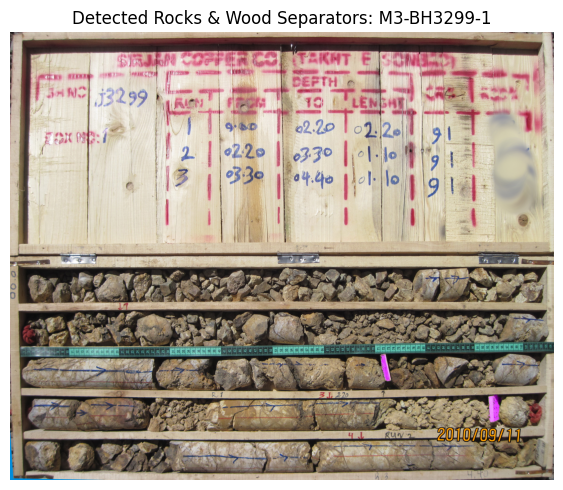

In [14]:
sample_test_name = list(test_image_files.keys())[0]
sample_test_path = test_image_files[sample_test_name]

img_rgb = cv2.cvtColor(cv2.imread(sample_test_path), cv2.COLOR_BGR2RGB)
res = model.predict(source=sample_test_path, conf=0.25, device=device, verbose=False)[0]

fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(img_rgb)

for box in res.boxes:
    cls_id = int(box.cls.item())
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    color = 'lime' if cls_id == 0 else 'magenta'
    label = '+10cm rock' if cls_id == 0 else 'wood'
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2)
    ax.add_patch(rect)
    ax.text(x1, max(15, y1 - 5), label, color='white', fontsize=8,
            bbox=dict(facecolor=color, alpha=0.6, pad=1))

ax.set_title(f"Detected Rocks & Wood Separators: {sample_test_name}")
ax.axis('off')
plt.tight_layout()
plt.show()